# import library

In [27]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import plotly.express as ex 
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR  # for Regression
from lightgbm import LGBMRegressor
from IPython.display import display

### 📦 Libraries Used

- **NumPy** – numerical computations
- **Pandas** – data manipulation and analysis
- **Matplotlib & Seaborn** – data visualization
- **Plotly Express** – interactive visualizations
- **Scikit-learn** – preprocessing, pipelines, model training & evaluation
  - Linear, Lasso, Ridge, ElasticNet
  - KNN, Decision Tree, Random Forest, SVR
  - StandardScaler, Pipeline, RandomizedSearchCV
- **LightGBM** – gradient boosting regressor for high-performance modeling

In [17]:
def read_data(path) -> pd.DataFrame:
    d = pd.read_csv(path)
    return d

In [19]:
data = read_data(path="medical_insurance.csv")

In [5]:
df = pd.DataFrame(data)

In [20]:
df

,age,gender,bmi,children,discount_eligibility,region,expenses,premium
0,19,female,27.9,0,yes,southwest,16884.92,168.8492
1,18,male,33.8,1,no,southeast,1725.55,17.2555
2,28,male,33.0,3,no,southeast,4449.46,44.4946
3,33,male,22.7,0,no,northwest,21984.47,439.6894
4,32,male,28.9,0,no,northwest,3866.86,77.3372
...,...,...,...,...,...,...,...,...
1333,50,male,31.0,3,no,northwest,10600.55,212.0110
1334,18,female,31.9,0,no,northeast,2205.98,22.0598
1335,18,female,36.9,0,no,southeast,1629.83,16.2983
1336,21,female,25.8,0,no,southwest,2007.95,20.0795


In [12]:
def shape(data:pd.DataFrame):
    print(f"row --> {row}")
    print(f"columns --> {col}")

In [13]:
shape(df)

row --> 1338
columns --> 8


In [37]:
def information(data: pd.DataFrame):
    print(data.info())
    print("_" * 80)
    df_missing_value = pd.DataFrame(
        data={
            "count missing value": data.isna().sum(),
            "Ratio of missing values ​​to total data": (df.isna().any(axis=1).sum())
            / len(df),
            "Percentage of missing values ​​to total data": (
                (df.isna().any(axis=1).sum()) / len(df)
            )
            * 100,
        }
    )
    display(df_missing_value)
    print("_" * 100)
    print(f"unique value in each columns:\n")
    for colmn in df.columns:
        print(f"unique value in {colmn}:\n{df[colmn].unique()}")
        print("_" * 80)

In [38]:
information(df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1338 non-null   int64  
 1   gender                1338 non-null   object 
 2   bmi                   1338 non-null   float64
 3   children              1338 non-null   int64  
 4   discount_eligibility  1338 non-null   object 
 5   region                1338 non-null   object 
 6   expenses              1338 non-null   float64
 7   premium               1338 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 83.8+ KB
None
________________________________________________________________________________


,count missing value,Ratio of missing values ​​to total data,Percentage of missing values ​​to total data
age,0,0.0,0.0
gender,0,0.0,0.0
bmi,0,0.0,0.0
children,0,0.0,0.0
discount_eligibility,0,0.0,0.0
region,0,0.0,0.0
expenses,0,0.0,0.0
premium,0,0.0,0.0


____________________________________________________________________________________________________
unique value in each columns:

unique value in age:
[19 18 28 33 32 31 46 37 60 25 62 23 56 27 52 30 34 59 63 55 22 26 35 24
 41 38 36 21 48 40 58 53 43 64 20 61 44 57 29 45 54 49 47 51 42 50 39]
________________________________________________________________________________
unique value in gender:
['female' 'male']
________________________________________________________________________________
unique value in bmi:
[27.9 33.8 33.  22.7 28.9 25.7 33.4 27.7 29.8 25.8 26.2 26.3 34.4 39.8
 42.1 24.6 30.8 23.8 40.3 35.3 36.  32.4 34.1 31.9 28.  23.1 32.8 17.4
 36.3 35.6 28.6 28.3 36.4 20.4 20.8 36.7 39.9 26.6 36.6 21.8 37.1 37.3
 38.7 34.8 24.5 35.2 33.6 28.7 37.  31.8 31.7 22.9 27.4 33.7 24.7 25.9
 22.4 39.1 36.2 24.  24.8 28.5 28.1 32.  34.  29.6 35.5 26.9 38.3 37.6
 41.2 31.2 27.2 27.  39.5 31.3 20.  19.3 31.6 25.5 30.1 29.9 27.5 28.4
 30.9 35.1 29.7 35.7 32.2 49.1 23.4 29.  31.4 33.9 2

### ✅ Summery
---
- There was no missing value
- There were no wrong values
- The column data type was also correct

**Note**:
I divide EDA into 3 parts
Because we have 2 targets:
1. Part 1:
Initial EDA including data distribution analysis, noise analysis, outlier analysis, etc.
2. Part 2:
Investigation of the impact of each column on the first target
3. Part 3:
Investigation of the impact of each column on the second target

### Part 1:Initial EDA including data distribution analysis, noise analysis, outlier analysis, etc.

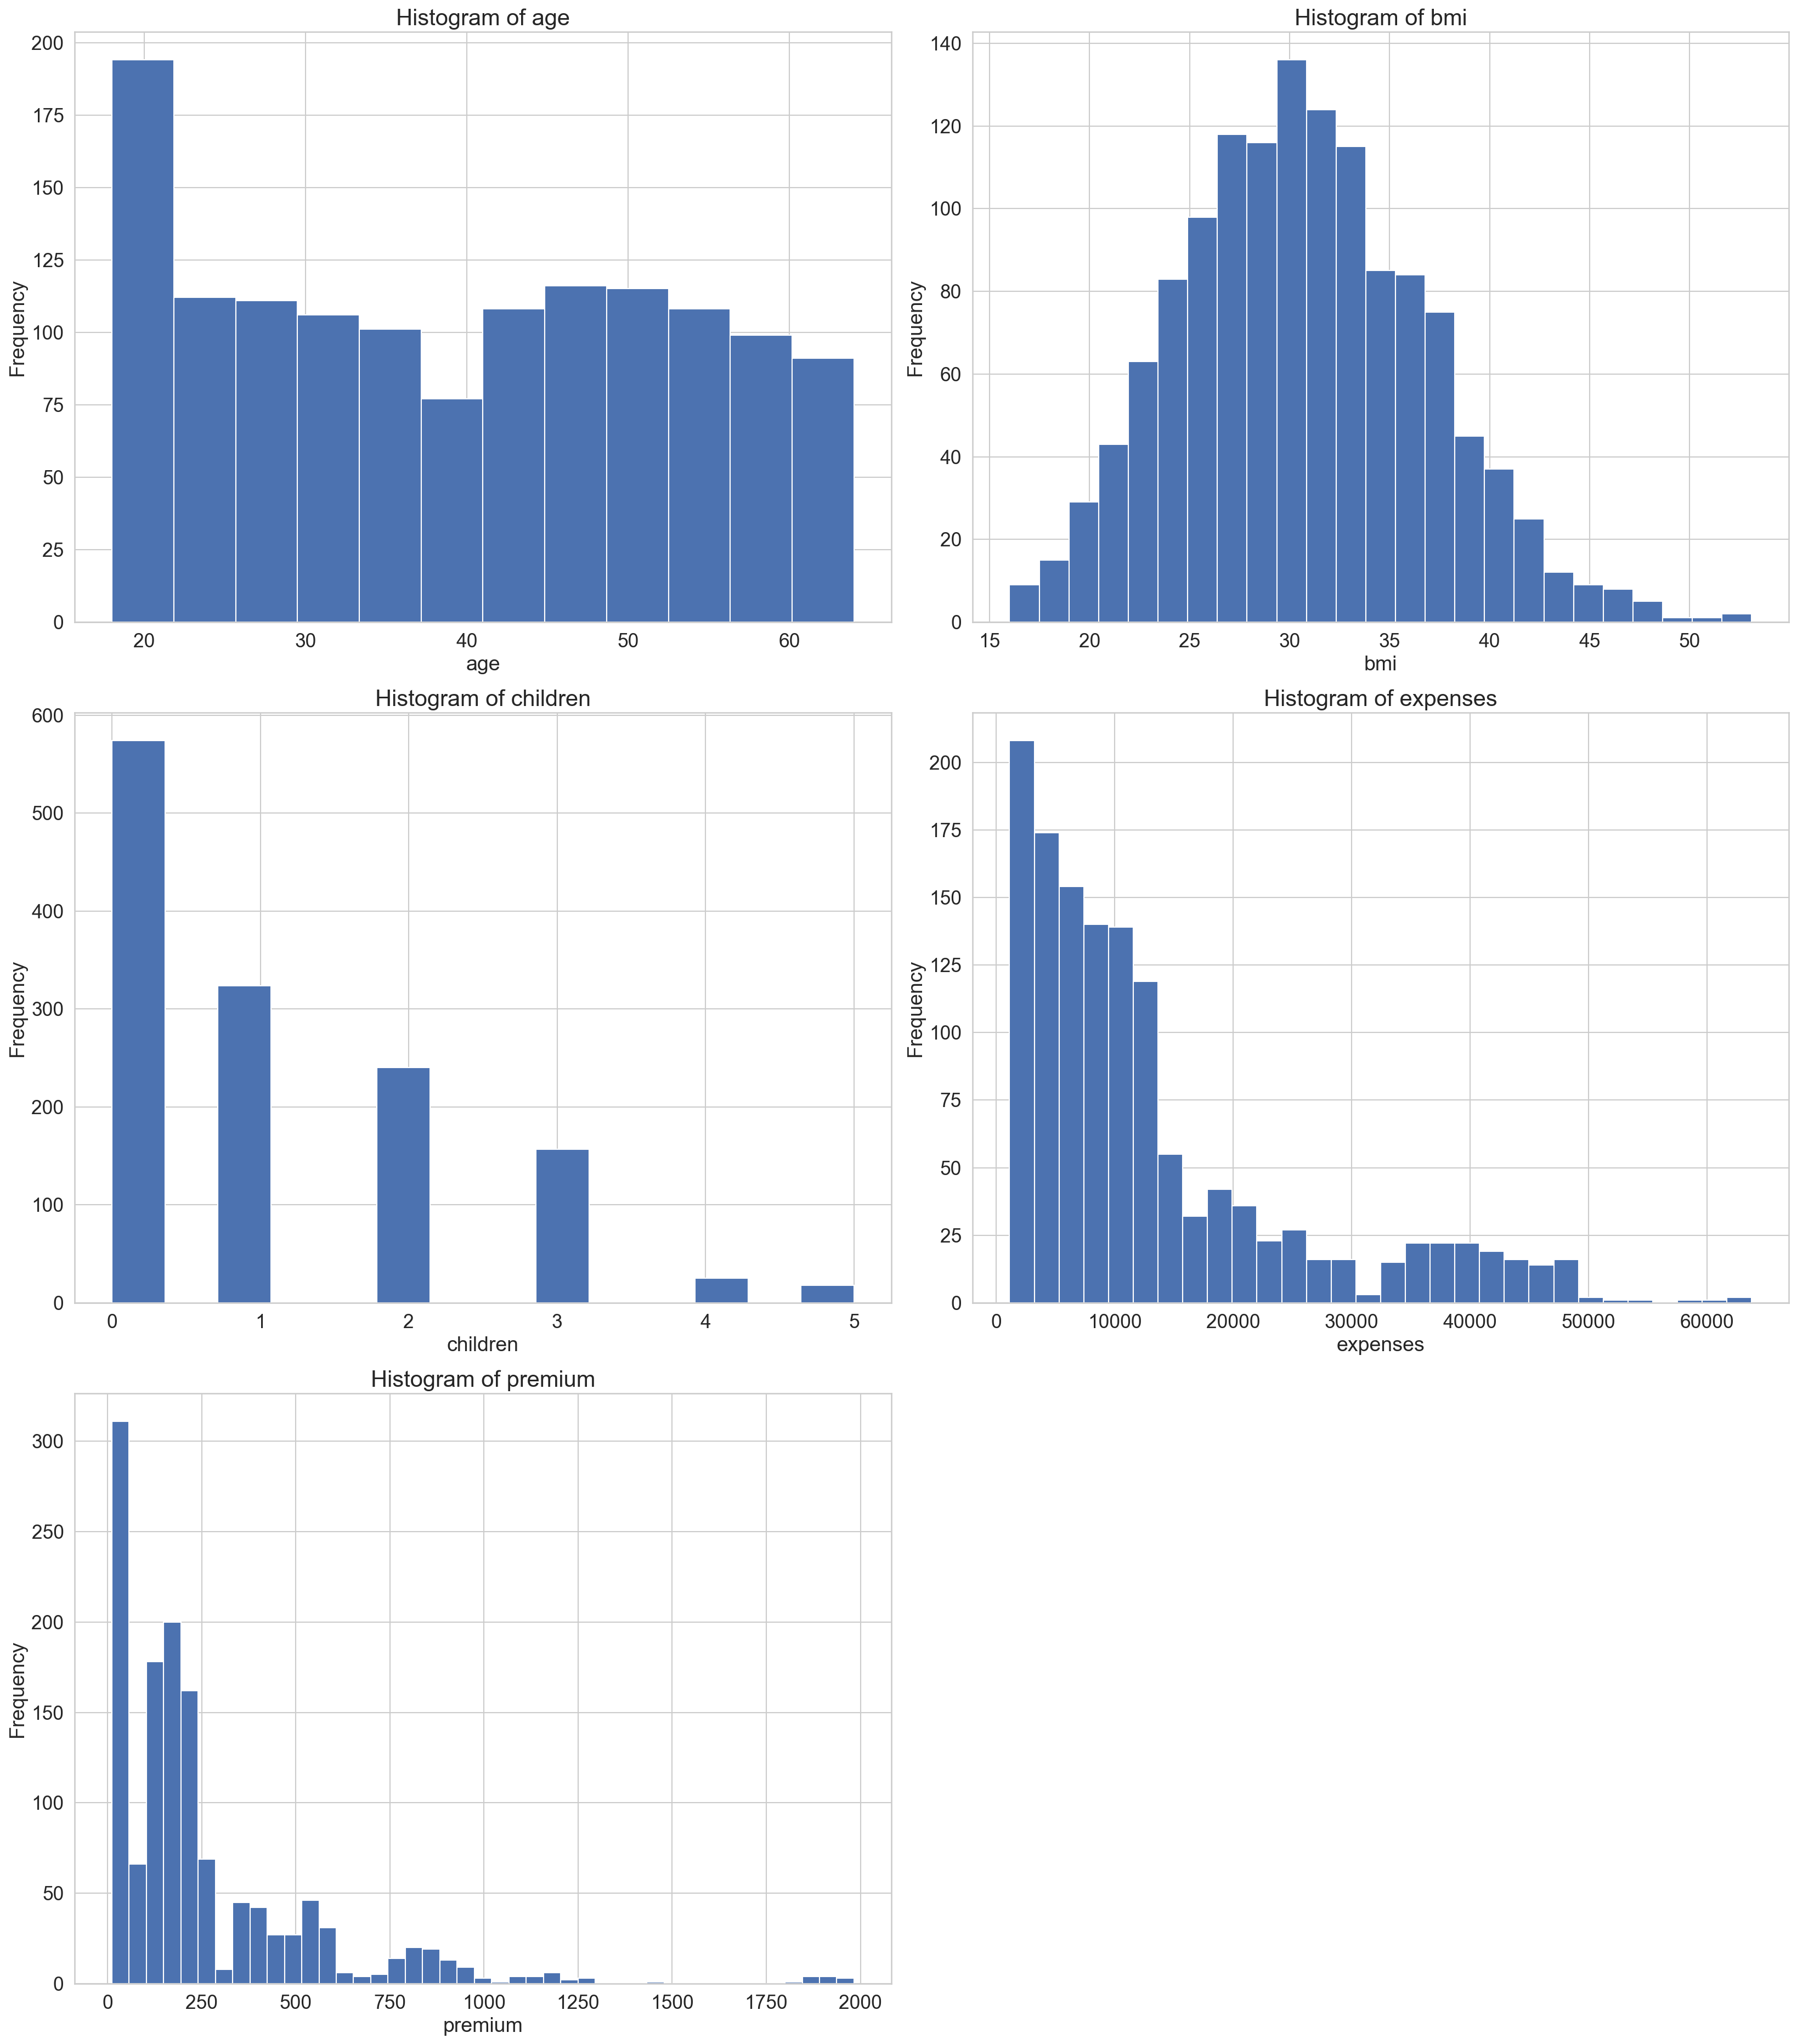

In [50]:
df_num = df.select_dtypes(include="number")

sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(22, 25),
    dpi=150
)

axes = axes.flatten()

for ax, col in zip(axes, df_num.columns):
    sns.histplot(df_num[col], bins="auto", ax=ax, alpha=1)
    ax.set_title(f"Histogram of {col}", fontsize=20)
    ax.set_xlabel(col, fontsize=18)
    ax.set_ylabel("Frequency", fontsize=18)
    ax.tick_params(axis="both", labelsize=17)

for ax in axes[len(df_num.columns):]:
    ax.axis("off")

plt.tight_layout()
plt.show()
